# Guia de estatística descritiva — Módulo I

**Disciplina:** Métodos e Técnicas de Pesquisa Quantitativa — Administração/UFMA
**Docente:** Prof. Dr. Tadeu Gomes Teixeira

> **O que é este guia.** A estatística descritiva da disciplina inteira, em um arquivo
> só: os 41 itens dos encontros 1 a 4, cada um com a fórmula comentada, o código mínimo
> e a conferência. É o lugar onde procurar “qual é a fórmula da variância?” ou “que
> medida uso numa variável ordinal?”. **Já vem executado**: você abre e lê o resultado.
>
> **Como usar**
> 1. Procure o item no índice abaixo pelo código (por exemplo, **4.5** é o coeficiente
>    de variação).
> 2. Leia as três células do item: a **fórmula comentada** (texto), o **código mínimo**
>    e a **conferência**, que mostra `[ok]` quando o número bate com o dos slides.
> 3. Para aplicar à base do seu projeto, use o modo **Encomenda**: cole a célula de
>    código e o cartão de contexto da sua base no assistente, peça a mesma conta na sua
>    coluna, cole na célula cinza do seu notebook e confira.
>
> **Nas avaliações.** O guia é material de consulta nas partes práticas (AV1 Parte B,
> AV2, AV3 e prova final Parte B). Nas partes conceituais, sem consulta, ele fica
> fechado. Você não escreve código: executa, lê e escreve a frase.

---

## Painel do guia

As bases são as mesmas dos encontros 1 a 4, e os números esperados são os mesmos dos
slides. Todas vêm dos arquivos CSV do diretório `dados/` do repositório.

| Base | Arquivo | Fonte | Recorte | Nível | Itens |
|---|---|---|---|---|---|
| Empresas por seção da CNAE | `cempre_maranhao.csv`, `cempre_brasil.csv` | IBGE, CEMPRE, tabela 9582 | Maranhão e Brasil, 2024 | nominal + contagem | 1.1 a 1.10 |
| Empresas por seção da CNAE | `cempre_secoes_cnae_brasil.csv` | IBGE, CEMPRE, tabela 9582 | Brasil, 2024 | nominal | 2.1, 3.5 |
| Nascimentos e sobrevivência por faixa de pessoal | `demografia_sobrevivencia_empresas.csv` | IBGE, Demografia das Empresas, tabela 9949 | Brasil, coortes de 2017 a 2021 | ordinal + taxa | 1.7, 2.2, 2.9, 3.4 |
| Serviços de alojamento e alimentação | `pas_alojamento_alimentacao.csv` | IBGE, PAS, tabela 2325 | Brasil, 2001 | razão | 2.3, 2.4 |
| IPCA, variação mensal | `bcb_ipca_mensal.csv` | Banco Central, SGS 433 | 2023-09 a 2026-08 (36 meses) | razão | 1.9, 3.1 a 3.8, 4.5, 4.13 |
| Inadimplência da carteira PJ | `bcb_inadimplencia_pj.csv` | Banco Central, SGS 21086 | 2023-08 a 2026-07 (36 meses) | razão | 3.1, 3.3, 3.6, 3.8 |
| Preços de revenda de combustíveis | `anp_precos_revenda_ma_2025.csv` | ANP, SHPC | Maranhão, 2025 (10.641 posto-mês; 4.816 de gasolina comum) | razão | 1.3, 1.4, 2.4, 3.5, 3.6, 4.2 a 4.14 |

### Índice dos itens

**Seção 1 · Ler um conjunto de dados: frequência e o denominador (encontro 1)**
1.1 Dado e informação · 1.2 Observação e variável · 1.3 Base de registros e base
agregada · 1.4 Frequência absoluta · 1.5 Frequência relativa · 1.6 Porcentagem e o
denominador · 1.7 Razão, proporção e taxa · 1.8 Ponto percentual e variação em por cento
· 1.9 Base 100 e número-índice · 1.10 Ler uma tabela

**Seção 2 · Tipos de dado e a regra da medida (encontro 2)**
2.1 Qualitativa nominal · 2.2 Qualitativa ordinal · 2.3 Quantitativa discreta ·
2.4 Quantitativa contínua · 2.5 Os níveis de Stevens · 2.6 O que cada nível permite e o
zero que não é zero · 2.7 A tabela de decisão · 2.8 Codificar no pandas · 2.9 Frequência
acumulada em ordinal

**Seção 3 · Tendência central (encontro 3)**
3.1 Média · 3.2 Média ponderada · 3.3 Mediana · 3.4 Mediana em dados ordinais · 3.5 Moda ·
3.6 Qual usar · 3.7 O valor extremo · 3.8 Média perto da mediana: a regra de bolso

**Seção 4 · Dispersão e forma da distribuição (encontro 4)**
4.1 Por que dispersão · 4.2 Amplitude · 4.3 Variância · 4.4 Desvio padrão ·
4.5 Coeficiente de variação · 4.6 Intervalo interquartílico · 4.7 Sensibilidade ao valor
extremo · 4.8 Distribuição de frequência e classes · 4.9 Amplitude e número de classes ·
4.10 Histograma · 4.11 Quartis e os cinco números · 4.12 Boxplot · 4.13 Escore z ·
4.14 Assimetria

**Fecho · A tabela de decisão: nível → posição → dispersão → gráfico**

> **Regra de ouro do semestre:** *a IA explica, o código calcula e você confere e
> escreve.* Nenhum número vai para o relatório sem ter saído de uma célula executada.

## Utilitários do guia

As duas células abaixo preparam tudo o que o guia usa. **Não precisa alterá-las.** A
primeira traz `conferir` e `cartao`, as mesmas funções dos notebooks dos encontros. A
segunda carrega as bases: primeiro do GitHub e, sem internet, da cópia local do
diretório `dados/` (ou de um arquivo que você tenha feito upload).

In [1]:

# =====================================================================
#  UTILITARIOS DA DISCIPLINA - nao precisa alterar nada daqui para baixo
#  estas duas funcoes sao usadas pelas celulas do encontro. Se voce nao
#  sabe o que elas fazem, tudo bem: nao mexa. Voce so precisa executar.
# =====================================================================

def conferir(descricao, obtido, esperado, tolerancia=0.005, unidade="%"):
    """Confere o resultado calculado contra o valor ja resolvido no slide.

    Chame assim:  conferir("taxa de sobrevivencia do setor X", obtido, 0.412)

    O 'esperado' e o numero que ja estava escrito no slide, resolvido a mao
    pelo professor. Se aparecer [ok], o seu calculo esta certo. Se aparecer
    [X], confira a base, o filtro e a coluna que voce usou.
    """
    try:
        dif = abs(float(obtido) - float(esperado))
    except (TypeError, ValueError):
        print("  [X ] nao deu para comparar: obtido = %r" % (obtido,))
        return
    num = lambda v: ("%.*f%s" % (2, v, unidade)) if unidade else ("%.4f" % v)
    if dif <= tolerancia:
        print("  [ok] %-54s obtido %-9s esperado %s"
              % (descricao[:54], num(float(obtido)), num(float(esperado))))
    else:
        print("  [X ] %-54s obtido %-9s esperado %-9s dif %s"
              % (descricao[:54], num(float(obtido)), num(float(esperado)), num(dif)))


def cartao(df, coluna, nome_base="base"):
    """Imprime o contexto que voce precisa colar no assistente de IA.

    Chame assim:  cartao(dados, "porte")

    Copie a saida inteira e cole no pedido. E isso que impede a IA de
    inventar numero: ela so pode usar o que esta escrito no cartao.
    """
    print("=== CARTAO DE CONTEXTO (copie tudo daqui para o assistente) ===")
    print("base: %s" % nome_base)
    print("linhas x colunas: %d x %d" % df.shape)
    print("colunas e seu significado:")
    for c in df.columns:
        print("   - %s (%s)" % (c, df[c].dtype))
    if coluna in df.columns:
        print("valores unicos de '%s': %s"
              % (coluna, sorted(map(str, df[coluna].dropna().unique()))[:25]))
    print("=== fim do cartao ===")


print("Utilitarios carregados: conferir() e cartao() estao prontas para uso.")


Utilitarios carregados: conferir() e cartao() estao prontas para uso.


In [2]:
# =====================================================================
#  CARGA DAS BASES DO GUIA - nao precisa alterar nada aqui
#  le os CSVs de dados/ do GitHub; sem internet, da copia local
# =====================================================================
import io
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = ("https://raw.githubusercontent.com/tadeugomes/"
       "metodos-pesquisa-quantitativa/main/dados/")
ORIGEM = {}


def carrega(arquivo, **opcoes):
    """Le um CSV do diretorio dados/: do GitHub ou, sem internet, da copia local."""
    try:
        with urllib.request.urlopen(RAW + arquivo, timeout=60) as resposta:
            tabela = pd.read_csv(io.BytesIO(resposta.read()), **opcoes)
        ORIGEM[arquivo] = "GitHub"
        return tabela
    except Exception:
        for caminho in (os.path.join("dados", arquivo), arquivo):
            if os.path.exists(caminho):
                ORIGEM[arquivo] = "copia local"
                return pd.read_csv(caminho, **opcoes)
        raise


def br(valor, casas=2):
    """Numero no formato brasileiro: 168.098 e 41,36."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def limpa_cempre(bruto):
    """Tabela 9582 do SIDRA: secao, letra, valor, unidade e ano, sem a linha Total."""
    t = pd.DataFrame({
        "secao_cnae": bruto["D4N"],
        "letra": bruto["D4N"].str.slice(0, 1),
        "Valor": pd.to_numeric(bruto["V"], errors="coerce"),  # "-" vira vazio
        "unidade": bruto["MN"],
        "ano": bruto["D2N"].astype(int),
    })
    return t[t["secao_cnae"] != "Total"].dropna(subset=["Valor"]).reset_index(drop=True)


# --- encontro 1: CEMPRE, empresas por secao da CNAE (a 2a linha do CSV e descricao)
cempre_ma_bruto = carrega("cempre_maranhao.csv", skiprows=[1])
cempre_br_bruto = carrega("cempre_brasil.csv", skiprows=[1])
cempre_ma = limpa_cempre(cempre_ma_bruto)
cempre_br = limpa_cempre(cempre_br_bruto)

# --- encontro 2: nominal (CNAE Brasil), ordinal (faixas) e razao (PAS)
nominal = carrega("cempre_secoes_cnae_brasil.csv")
demog = carrega("demografia_sobrevivencia_empresas.csv", skiprows=[1])
demog["V"] = pd.to_numeric(demog["V"], errors="coerce")
demog["D2N"] = demog["D2N"].astype(str)
# nascimentos de 2021 por faixa, na linha Total da CNAE. A faixa "Total" e as
# secoes ficam de fora: somadas as demais, contariam cada empresa duas vezes
ordinal = (demog[demog["D3N"].str.startswith("Número de nascimentos")
                 & (demog["D4N"] == "Total") & (demog["D2N"] == "2021")
                 & (demog["D5N"] != "Total")]
           .loc[:, ["D5N", "V"]]
           .rename(columns={"D5N": "faixa", "V": "nascimentos"})
           .reset_index(drop=True))
pas = carrega("pas_alojamento_alimentacao.csv")

# --- encontro 3: duas series mensais do Banco Central
ipca = carrega("bcb_ipca_mensal.csv")
inad = carrega("bcb_inadimplencia_pj.csv")

# --- encontro 4: precos de revenda da ANP no Maranhao, 2025
anp = carrega("anp_precos_revenda_ma_2025.csv")
gasolina = anp.loc[anp["produto"] == "GASOLINA", "valor_venda"].dropna().reset_index(drop=True)

print("Bases carregadas:")
print(f"  CEMPRE Maranhão ........ {len(cempre_ma):>6} seções  ({ORIGEM['cempre_maranhao.csv']})")
print(f"  CEMPRE Brasil .......... {len(cempre_br):>6} seções  ({ORIGEM['cempre_brasil.csv']})")
print(f"  CNAE Brasil (nominal) .. {len(nominal):>6} seções  ({ORIGEM['cempre_secoes_cnae_brasil.csv']})")
print(f"  Faixas (ordinal) ....... {len(ordinal):>6} faixas  ({ORIGEM['demografia_sobrevivencia_empresas.csv']})")
print(f"  PAS (razão) ............ {len(pas):>6} variáveis ({ORIGEM['pas_alojamento_alimentacao.csv']})")
print(f"  IPCA mensal ............ {len(ipca):>6} meses  ({ORIGEM['bcb_ipca_mensal.csv']})")
print(f"  Inadimplência PJ ....... {len(inad):>6} meses  ({ORIGEM['bcb_inadimplencia_pj.csv']})")
print(f"  ANP Maranhão 2025 ...... {len(anp):>6} posto-mês, {len(gasolina)} de gasolina "
      f"({ORIGEM['anp_precos_revenda_ma_2025.csv']})")

Bases carregadas:
  CEMPRE Maranhão ........     20 seções  (GitHub)
  CEMPRE Brasil ..........     20 seções  (GitHub)
  CNAE Brasil (nominal) ..     20 seções  (GitHub)
  Faixas (ordinal) .......      3 faixas  (GitHub)
  PAS (razão) ............      4 variáveis (GitHub)
  IPCA mensal ............     36 meses  (GitHub)
  Inadimplência PJ .......     36 meses  (GitHub)
  ANP Maranhão 2025 ......  10641 posto-mês, 4816 de gasolina (GitHub)


---

## Seção 1 · Ler um conjunto de dados: frequência e o denominador

*Encontro 1. A pergunta do bloco:* **69.518 empresas de comércio no Maranhão. Quanto isso
representa?** A pergunta só fica completa quando se responde **“entre quem?”**.

**Glossário da seção**

| Termo | Em uma linha |
|---|---|
| **Observação** | Cada linha da base: uma empresa, uma seção, um posto em um mês |
| **Variável** | Cada coluna: o que foi medido em todas as observações |
| **Frequência absoluta** ($n_i$) | Quantas observações caem na categoria $i$ |
| **Frequência relativa** ($f_i$) | A contagem dividida pelo total, entre 0 e 1 |
| **Denominador** | O “todo” da divisão: é ele que decide a pergunta respondida |
| **Ponto percentual (p.p.)** | A diferença entre duas porcentagens |
| **Número-índice** | Uma série reescrita a partir de uma base igual a 100 |

### 1.1 Dado e informação

**Pergunta.** O que falta para um número dizer alguma coisa?

**Em linguagem corrente.** O **dado** é o número sozinho: `69518`. Ele vira
**informação** quando ganha cinco etiquetas: **o quê** (empresas da seção G, comércio),
**unidade** (empresas, contagem), **onde** (Maranhão), **quando** (2024) e **fonte**
(IBGE, CEMPRE).

**Use / não use.** Toda vez que um número for para o relatório, ele vai com as cinco
etiquetas. Nunca cite um número que você não sabe dizer de onde veio.

**Erro comum.** “O comércio tem 69.518” — 69.518 o quê, onde, quando?

In [3]:
linha = cempre_ma[cempre_ma["letra"] == "G"].iloc[0]
print("O dado:      ", br(linha["Valor"], 0))
print("A informação:", br(linha["Valor"], 0), "empresas da seção", linha["secao_cnae"][:40] + "...",
      "| Maranhão |", linha["ano"], "| IBGE, CEMPRE, tabela 9582")

O dado:       69.518
A informação: 69.518 empresas da seção G Comércio; reparação de veículos automo... | Maranhão | 2024 | IBGE, CEMPRE, tabela 9582


In [4]:
conferir("empresas de comércio no Maranhão", linha["Valor"], 69518, tolerancia=0.5, unidade="")
conferir("ano de referência", linha["ano"], 2024, tolerancia=0, unidade="")

  [ok] empresas de comércio no Maranhão                       obtido 69518.0000 esperado 69518.0000
  [ok] ano de referência                                      obtido 2024.0000 esperado 2024.0000


### 1.2 Observação (linha) e variável (coluna)

**Pergunta.** Do que é feita uma base de dados?

**Em linguagem corrente.** Toda base tem a mesma anatomia: **cada linha é uma
observação** (aqui, uma seção da CNAE) e **cada coluna é uma variável** (o nome da seção, a
letra, o número de empresas, a unidade, o ano). O formato da tabela é
$\text{linhas} \times \text{colunas}$.

**Use / não use.** Antes de qualquer conta, diga em voz alta o que é **uma linha**. Se
você não sabe o que a linha representa, não sabe o que está contando.

**Frase.** “A base tem 20 observações (as seções da CNAE com valor no Maranhão) e 5
variáveis.”

In [5]:
linhas, colunas = cempre_ma.shape
print(f"{linhas} observações (linhas) x {colunas} variáveis (colunas)")
print("As variáveis:", list(cempre_ma.columns))
cempre_ma[["letra", "secao_cnae", "Valor"]].head(3)

20 observações (linhas) x 5 variáveis (colunas)
As variáveis: ['secao_cnae', 'letra', 'Valor', 'unidade', 'ano']


,letra,secao_cnae,Valor
0,A,"A Agricultura, pecuária, produção florestal, p...",2012.0
1,B,B Indústrias extrativas,268.0
2,C,C Indústrias de transformação,6386.0


In [6]:
conferir("observações: seções da CNAE no Maranhão", linhas, 20, tolerancia=0, unidade="")
conferir("variáveis da tabela limpa", colunas, 5, tolerancia=0, unidade="")

  [ok] observações: seções da CNAE no Maranhão                obtido 20.0000   esperado 20.0000
  [ok] variáveis da tabela limpa                              obtido 5.0000    esperado 5.0000


### 1.3 Base de registros individuais e base agregada

**Pergunta.** Contar linhas é contar casos?

**Em linguagem corrente.** Numa **base de registros** cada linha é um caso (um posto em um
mês, na ANP): contar linhas é contar casos. Numa **base agregada** cada linha já é um
grupo contado por alguém (uma seção da CNAE, no CEMPRE): o número de casos está **numa
coluna**, e contar linhas dá só o número de grupos.

**Use / não use.** Em base agregada, some a coluna de contagem; nunca use `len()` para
contar empresas. E só a base de registros permite medir dispersão entre casos (encontro 4).

In [7]:
print("Base de REGISTROS (ANP): cada linha é um posto em um mês")
print("  linhas =", br(len(anp), 0), "observações  |  de gasolina comum:", br(len(gasolina), 0))
print()
print("Base AGREGADA (CEMPRE): cada linha é uma seção já contada pelo IBGE")
print("  linhas =", len(cempre_ma), "seções  |  empresas (soma da coluna Valor):",
      br(cempre_ma["Valor"].sum(), 0))

Base de REGISTROS (ANP): cada linha é um posto em um mês
  linhas = 10.641 observações  |  de gasolina comum: 4.816

Base AGREGADA (CEMPRE): cada linha é uma seção já contada pelo IBGE
  linhas = 20 seções  |  empresas (soma da coluna Valor): 168.098


In [8]:
conferir("linhas da base de registros (ANP)", len(anp), 10641, tolerancia=0, unidade="")
conferir("preços de gasolina comum", len(gasolina), 4816, tolerancia=0, unidade="")
conferir("empresas na base agregada (soma)", cempre_ma["Valor"].sum(), 168098, tolerancia=0.5, unidade="")

  [ok] linhas da base de registros (ANP)                      obtido 10641.0000 esperado 10641.0000
  [ok] preços de gasolina comum                               obtido 4816.0000 esperado 4816.0000
  [ok] empresas na base agregada (soma)                       obtido 168098.0000 esperado 168098.0000


### 1.4 Frequência absoluta

**Pergunta.** Quantos são?

**Fórmula.** $n_i$ = número de observações na categoria $i$.

**Em linguagem corrente.** Contar é o início de tudo. Na base de registros, quem conta é o
código (`value_counts`); na base agregada, o IBGE já contou e o número está na coluna.

**Use / não use.** Use quando a pergunta é “quantos” e a resposta é um inteiro. Não use
sozinha para comparar recortes de tamanhos diferentes: 69.518 no Maranhão e 2.908.372 no
Brasil não se comparam sem dividir pelo total.

In [9]:
print("Contando na base de registros (ANP): postos-mês por produto")
print(anp["produto"].value_counts().to_string())
print()
n_g = cempre_ma.loc[cempre_ma["letra"] == "G", "Valor"].iloc[0]
print("Já contado na base agregada: empresas de comércio no Maranhão, n_G =", br(n_g, 0))

Contando na base de registros (ANP): postos-mês por produto
produto
GASOLINA              4816
GASOLINA ADITIVADA    2964
ETANOL                2861

Já contado na base agregada: empresas de comércio no Maranhão, n_G = 69.518


In [10]:
conferir("gasolina comum (n_i, contado pelo código)", anp["produto"].value_counts()["GASOLINA"], 4816, tolerancia=0, unidade="")
conferir("comércio no Maranhão (n_i, contado pelo IBGE)", n_g, 69518, tolerancia=0.5, unidade="")

  [ok] gasolina comum (n_i, contado pelo código)              obtido 4816.0000 esperado 4816.0000
  [ok] comércio no Maranhão (n_i, contado pelo IBGE)          obtido 69518.0000 esperado 69518.0000


### 1.5 Frequência relativa

**Pergunta.** Que parte do todo é essa categoria?

**Fórmula.**
$$f_i = \frac{n_i}{n} \qquad \%_i = f_i \times 100$$

* $n_i$ é a contagem da categoria $i$; $n$ é o total de observações
* $f_i$ fica entre 0 e 1, e a soma de todas as $f_i$ é **sempre 1** (100%)

**Em linguagem corrente.** Conte a categoria e divida pelo total. A soma que fecha em 100%
é a primeira conferência de qualquer tabela de frequências.

**Frase.** “Em 2024, 69.518 das 168.098 empresas do Maranhão (41,4%) eram de comércio
(IBGE, CEMPRE).”

In [11]:
tabela = cempre_ma[["letra", "Valor"]].rename(columns={"Valor": "n_i"})
n = tabela["n_i"].sum()                       # o denominador, à vista
tabela["f"] = tabela["n_i"] / n
f_g = tabela.loc[tabela["letra"] == "G", "f"].iloc[0]
print("n =", br(n, 0), "| f do comércio =", round(f_g, 4), "| soma das f =", round(tabela["f"].sum(), 4))
tabela.sort_values("n_i", ascending=False).head(5)

n = 168.098 | f do comércio = 0.4136 | soma das f = 1.0


,letra,n_i,f
6,G,69518.0,0.413556
18,S,22156.0,0.131804
12,M,11032.0,0.065628
16,Q,10113.0,0.060161
13,N,8825.0,0.052499


In [12]:
conferir("frequência relativa do comércio", f_g, 0.4136, tolerancia=0.0005, unidade="")
conferir("soma das frequências relativas", tabela["f"].sum(), 1.0, tolerancia=0.0001, unidade="")

  [ok] frequência relativa do comércio                        obtido 0.4136    esperado 0.4136
  [ok] soma das frequências relativas                         obtido 1.0000    esperado 1.0000


### 1.6 Porcentagem e o denominador

**Pergunta.** “Quanto isso representa?” — **entre quem?**

**Fórmula.** $\% = \dfrac{\text{numerador}}{\text{denominador}} \times 100$. O numerador é
o mesmo nas três contas abaixo; muda o denominador, e muda a pergunta.

| Denominador | Pergunta completa | Resultado |
|---|---|---|
| 168.098, todas as empresas do MA | Das empresas do Maranhão, quantas são de comércio? | 41,36% |
| 2.908.372, comércio do Brasil | Das empresas de comércio do Brasil, quantas estão no MA? | 2,39% |
| 10.607.110, todas as do Brasil | Das empresas do Brasil, quantas são comércio do MA? | 0,66% |

**Erro comum.** Apresentar o resultado de uma pergunta como resposta de outra. As três
contas estão certas; a frase é que precisa dizer qual delas foi feita.

In [13]:
numerador  = n_g                                                       # comércio do MA
den_ma     = cempre_ma["Valor"].sum()                                  # empresas do MA
den_com_br = cempre_br.loc[cempre_br["letra"] == "G", "Valor"].iloc[0] # comércio do Brasil
den_br     = cempre_br["Valor"].sum()                                  # empresas do Brasil
print(br(numerador, 0), "de", br(den_ma, 0), "=", br(numerador / den_ma * 100), "%")
print(br(numerador, 0), "de", br(den_com_br, 0), "=", br(numerador / den_com_br * 100), "%")
print(br(numerador, 0), "de", br(den_br, 0), "=", br(numerador / den_br * 100), "%")

69.518 de 168.098 = 41,36 %
69.518 de 2.908.372 = 2,39 %
69.518 de 10.607.110 = 0,66 %


In [14]:
conferir("comércio do MA / empresas do MA", numerador / den_ma * 100, 41.36, tolerancia=0.01)
conferir("comércio do MA / comércio do Brasil", numerador / den_com_br * 100, 2.39, tolerancia=0.01)
conferir("comércio do MA / empresas do Brasil", numerador / den_br * 100, 0.66, tolerancia=0.01)

  [ok] comércio do MA / empresas do MA                        obtido 41.36%    esperado 41.36%
  [ok] comércio do MA / comércio do Brasil                    obtido 2.39%     esperado 2.39%
  [ok] comércio do MA / empresas do Brasil                    obtido 0.66%     esperado 0.66%


### 1.7 Razão, proporção e taxa

**Pergunta.** Três divisões que a Administração confunde: o que cada uma divide por quê?

| Divisão | Fórmula | Lê-se | Exemplo |
|---|---|---|---|
| **Proporção** | parte ÷ todo | “que parte do todo” | comércio ÷ empresas do MA = 0,41 |
| **Razão** | uma parte ÷ outra parte | “quantos de A para cada B” | comércio ÷ outras atividades de serviços (S) = 3,14 |
| **Taxa** | eventos ÷ expostos, **em um período** | “quantos, de cada 100, em tanto tempo” | empresas que sobreviveram 3 anos ÷ empresas nascidas |

**Em linguagem corrente.** A proporção fica entre 0 e 1; a razão pode passar de 1; a taxa
tem **tempo** dentro dela — sem o período, ela não se lê.

**Frase.** “Das empresas empregadoras nascidas no Brasil em 2019, 54,3% sobreviveram três
anos (IBGE, Demografia das Empresas).”

In [15]:
n_s = cempre_ma.loc[cempre_ma["letra"] == "S", "Valor"].iloc[0]
proporcao = n_g / den_ma
razao = n_g / n_s
taxa3 = demog[(demog["D3N"] == "Taxa de 3 anos de sobrevivência") & (demog["D4N"] == "Total")
              & (demog["D2N"] == "2019")].set_index("D5N")["V"]
print("proporção: comércio / todas as empresas do MA   =", round(proporcao, 4))
print("razão:     comércio / outras atividades (S)     =", round(razao, 2), "empresas de G para cada uma de S")
print("taxa de sobrevivência em 3 anos, coorte de 2019 (%):")
print(taxa3.round(2).to_string())

proporção: comércio / todas as empresas do MA   = 0.4136
razão:     comércio / outras atividades (S)     = 3.14 empresas de G para cada uma de S
taxa de sobrevivência em 3 anos, coorte de 2019 (%):
D5N
Total                 54.29
1 a 9 pessoas         52.75
10 a 49 pessoas       72.38
50 ou mais pessoas    76.06


In [16]:
conferir("proporção: comércio / empresas do MA", proporcao, 0.4136, tolerancia=0.0005, unidade="")
conferir("razão: comércio / outras atividades (S)", razao, 3.14, tolerancia=0.005, unidade="")
conferir("taxa de sobrevivência em 3 anos, total", taxa3["Total"], 54.29, tolerancia=0.01)

  [ok] proporção: comércio / empresas do MA                   obtido 0.4136    esperado 0.4136


  [ok] razão: comércio / outras atividades (S)                obtido 3.1377    esperado 3.1400
  [ok] taxa de sobrevivência em 3 anos, total                 obtido 54.29%    esperado 54.29%


### 1.8 Ponto percentual e variação em por cento

**Pergunta.** O comércio pesa 41,36% no Maranhão e 27,42% no Brasil. Quanto a mais?

**Fórmulas.**
$$\text{diferença em p.p.} = \%_A - \%_B \qquad
\text{variação em \%} = \left(\frac{\%_A}{\%_B} - 1\right) \times 100$$

**Em linguagem corrente.** A diferença entre duas porcentagens se diz em **pontos
percentuais**: 41,36 − 27,42 = **13,94 p.p.** A variação relativa (50,8%) é outra conta e
responde a outra pergunta. “O comércio é 51% maior no Maranhão” é a leitura errada.

**Frase.** “O comércio reúne 41,4% das empresas do Maranhão, 13,9 pontos percentuais acima
da participação no Brasil (27,4%).”

In [17]:
pct_ma = n_g / den_ma * 100
pct_br = den_com_br / den_br * 100
print("Maranhão:", br(pct_ma), "%  |  Brasil:", br(pct_br), "%")
print("diferença em pontos percentuais:", br(pct_ma - pct_br), "p.p.")
print("variação em por cento:          ", br((pct_ma / pct_br - 1) * 100), "%  (outra pergunta)")

Maranhão: 41,36 %  |  Brasil: 27,42 %
diferença em pontos percentuais: 13,94 p.p.
variação em por cento:           50,83 %  (outra pergunta)


In [18]:
conferir("participação do comércio no Brasil", pct_br, 27.42, tolerancia=0.01)
conferir("diferença MA - Brasil (p.p.)", pct_ma - pct_br, 13.94, tolerancia=0.01, unidade=" p.p.")
conferir("variação relativa (%)", (pct_ma / pct_br - 1) * 100, 50.83, tolerancia=0.01)

  [ok] participação do comércio no Brasil                     obtido 27.42%    esperado 27.42%
  [ok] diferença MA - Brasil (p.p.)                           obtido 13.94 p.p. esperado 13.94 p.p.
  [ok] variação relativa (%)                                  obtido 50.83%    esperado 50.83%


### 1.9 Base 100 e número-índice

**Pergunta.** Quanto os preços subiram em três anos, se o Banco Central publica a variação
**mês a mês**?

**Fórmula.**
$$I_t = I_{t-1} \times \left(1 + \frac{v_t}{100}\right), \qquad I_0 = 100$$

* $v_t$ é a variação do mês $t$, em %; $I_t$ é o índice no mês $t$
* a variação acumulada é $I_{\text{final}} - 100$, em %

**Em linguagem corrente.** Comece em 100 e aplique cada variação sobre o valor anterior.
As variações se **multiplicam**, não se somam: somar os 36 meses dá 13,33%, e o acumulado
de verdade é 14,21%.

**Frase.** “Com base em agosto de 2023 = 100, o IPCA chegou a 114,21 em agosto de 2026: os
preços subiram 14,2% em três anos (Banco Central, SGS 433).”

In [19]:
ipca["indice"] = 100 * (1 + ipca["valor"] / 100).cumprod()     # base: agosto de 2023 = 100
print("índice no último mês (", ipca["data"].iloc[-1], "):", br(ipca["indice"].iloc[-1]))
print("variação acumulada:", br(ipca["indice"].iloc[-1] - 100), "%")
print("soma simples das variações (a conta errada):", br(ipca["valor"].sum()), "%")
ipca[["data", "valor", "indice"]].tail(3)

índice no último mês ( 2026-08 ): 114,21
variação acumulada: 14,21 %
soma simples das variações (a conta errada): 13,33 %


,data,valor,indice
33,2026-06,0.16,114.500309
34,2026-07,0.07,114.580460
35,2026-08,-0.32,114.213802


In [20]:
conferir("IPCA, índice final (ago/2023 = 100)", ipca["indice"].iloc[-1], 114.21, tolerancia=0.01, unidade="")
conferir("IPCA acumulado em 36 meses", ipca["indice"].iloc[-1] - 100, 14.21, tolerancia=0.01)

  [ok] IPCA, índice final (ago/2023 = 100)                    obtido 114.2138  esperado 114.2100
  [ok] IPCA acumulado em 36 meses                             obtido 14.21%    esperado 14.21%


### 1.10 Ler uma tabela: unidade, total, ordem das linhas e período

**Pergunta.** O que conferir antes de usar qualquer tabela?

**Os quatro pontos.**
1. **Unidade**: empresas, R$, mil R$, %? O CEMPRE diz “Unidades” — contagem de empresas;
2. **Total**: a tabela traz uma linha “Total”? Se ela entrar na soma, **cada empresa conta
   duas vezes**;
3. **Ordem das linhas**: o IBGE ordena pelo código (A a U), não pelo tamanho. A ordem da
   tabela não é ranking;
4. **Período de referência**: o ano do corte (aqui, 2024), que vai na frase.

**Erro comum.** Somar a coluna inteira com a linha Total dentro: 336.196 empresas, o dobro
das que existem. E ler o “-” da seção T como zero: no IBGE, “-” é **sem valor**.

In [21]:
valores = pd.to_numeric(cempre_ma_bruto["V"], errors="coerce")
print("unidade:", cempre_ma_bruto["MN"].iloc[0], "| período:", cempre_ma_bruto["D2N"].iloc[0])
print("soma COM a linha Total (errado):", br(valores.sum(), 0))
print("soma SEM a linha Total (certo): ", br(valores[cempre_ma_bruto["D4N"] != "Total"].sum(), 0))
print("linhas sem valor ('-'):", int(valores.isna().sum()), "->",
      cempre_ma_bruto.loc[valores.isna(), "D4N"].tolist())
print("primeiras letras na ordem do IBGE:", "".join(cempre_ma_bruto["D4N"].str.slice(0, 1).tolist()[1:8]))

unidade:

 Unidades | período: 2024
soma COM a linha Total (errado): 336.196
soma SEM a linha Total (certo):  168.098
linhas sem valor ('-'): 1 -> ['T Serviços domésticos']
primeiras letras na ordem do IBGE: ABCDEFG


In [22]:
conferir("soma com a linha Total (o erro)", valores.sum(), 336196, tolerancia=0.5, unidade="")
conferir("soma sem a linha Total", valores[cempre_ma_bruto["D4N"] != "Total"].sum(), 168098, tolerancia=0.5, unidade="")
conferir("linhas sem valor", valores.isna().sum(), 1, tolerancia=0, unidade="")

  [ok] soma com a linha Total (o erro)                        obtido 336196.0000 esperado 336196.0000
  [ok] soma sem a linha Total                                 obtido 168098.0000 esperado 168098.0000
  [ok] linhas sem valor                                       obtido 1.0000    esperado 1.0000


---

## Seção 2 · Tipos de dado e a regra da medida

*Encontro 2. A pergunta do bloco:* **uma empresa tem 0, 3 ou 27 funcionários. Posso
somar?** Depende do que o número significa: uma quantidade, que aceita conta, ou uma
etiqueta, que só identifica.

**Glossário da seção**

| Termo | Em uma linha |
|---|---|
| **Nominal** | Categorias sem ordem: só um nome |
| **Ordinal** | Categorias com ordem, sem distância definida |
| **Discreta** | Contagem: só valores inteiros |
| **Contínua** | Medição: qualquer valor de um intervalo |
| **Intervalo** | Distâncias iguais, zero escolhido por convenção |
| **Razão** | Distâncias iguais e zero que significa ausência |
| **`dtype`** | O tipo que o pandas atribui à coluna (`object`, `int64`, `float64`, `category`) |
| **Frequência acumulada** | A soma das frequências até a categoria, que só existe com ordem |

### 2.1 Variável qualitativa nominal

**Pergunta.** O que se pode fazer com uma variável que é só um nome?

**Em linguagem corrente.** A **seção da CNAE** é nominal: G (comércio) e C (indústria)
são rótulos. A letra C vem antes da G no alfabeto, mas isso não põe a indústria antes do
comércio em nada.

**O que cabe.** Contar, calcular a porcentagem e apontar a **moda** (a categoria mais
frequente). **Não cabe:** ordenar pela letra, somar, tirar média ou mediana.

**Frase.** “O comércio é a seção mais frequente do cadastro: 27,4% das 10.607.110 empresas
do Brasil (IBGE, CEMPRE, 2024).”

In [23]:
total_nom = nominal["Valor"].sum()
moda_nom = nominal.loc[nominal["Valor"].idxmax()]
print("total de empresas no Brasil:", br(total_nom, 0))
print("a moda:", moda_nom["letra"], "-", moda_nom["atividade"][:45], "|", br(moda_nom["pct"]), "%")
nominal[["letra", "atividade", "Valor", "pct"]].head(5)

total de empresas no Brasil:

 10.607.110
a moda: G - Comércio; reparação de veículos automotores e | 27,42 %


,letra,atividade,Valor,pct
0,G,Comércio; reparação de veículos automotores e ...,2908372.0,27.42
1,N,Atividades administrativas e serviços compleme...,1067934.0,10.07
2,M,"Atividades profissionais, científicas e técnicas",957541.0,9.03
3,S,Outras atividades de serviços,729492.0,6.88
4,Q,Saúde humana e serviços sociais,708067.0,6.68


In [24]:
conferir("total de empresas no Brasil", total_nom, 10607110, tolerancia=0.5, unidade="")
conferir("participação da moda (seção G)", moda_nom["pct"], 27.42, tolerancia=0.01)

  [ok] total de empresas no Brasil                            obtido 10607110.0000 esperado 10607110.0000
  [ok] participação da moda (seção G)                         obtido 27.42%    esperado 27.42%


### 2.2 Variável qualitativa ordinal

**Pergunta.** E quando as categorias têm ordem?

**Em linguagem corrente.** A **faixa de pessoal assalariado** é ordinal: 1 a 9, 10 a 49,
50 ou mais. Dá para dizer qual faixa é maior, mas não **quanto** maior: a distância entre
“1 a 9” e “10 a 49” não é um número.

**O que cabe.** Tudo o que cabe na nominal, mais **ordenar**, a **mediana** e a
**frequência acumulada**. **Não cabe:** a média.

**Base.** Nascimentos de empresas empregadoras no Brasil em 2021, linha Total da CNAE
(IBGE, Demografia das Empresas, tabela 9949).

In [25]:
print("faixas, na ordem natural:")
print(ordinal.to_string(index=False))
print("total de nascimentos em 2021:", br(ordinal["nascimentos"].sum(), 0))

faixas, na ordem natural:
             faixa  nascimentos
     1 a 9 pessoas     313749.0
   10 a 49 pessoas      21374.0
50 ou mais pessoas       2207.0
total de nascimentos em 2021: 337.330


In [26]:
conferir("faixas de pessoal (categorias)", len(ordinal), 3, tolerancia=0, unidade="")
conferir("nascimentos de empresas empregadoras, 2021", ordinal["nascimentos"].sum(), 337330, tolerancia=0.5, unidade="")

  [ok] faixas de pessoal (categorias)                         obtido 3.0000    esperado 3.0000
  [ok] nascimentos de empresas empregadoras, 2021             obtido 337330.0000 esperado 337330.0000


### 2.3 Variável quantitativa discreta

**Pergunta.** O que é uma contagem?

**Em linguagem corrente.** Número de empresas, de empregados, de filiais: só assume
**valores inteiros**. Não existe 0,5 empresa.

**Cuidado.** A **média** de uma variável discreta pode não ser inteira, e isso não é erro:
“5,05 pessoas por empresa” é um resumo do conjunto, não uma empresa real.

**Frase.** “Em 2001, as 281.133 empresas de alojamento e alimentação ocupavam 1.420.230
pessoas, cerca de 5 por empresa (IBGE, PAS).”

In [27]:
empresas = pas.loc[pas["variavel"] == "Número de empresas", "valor"].iloc[0]
pessoas = pas.loc[pas["variavel"].str.contains("Pessoal"), "valor"].iloc[0]
print("número de empresas:", br(empresas, 0), "| inteiro?", float(empresas).is_integer())
print("pessoal ocupado:   ", br(pessoas, 0), "| inteiro?", float(pessoas).is_integer())
print("pessoas por empresa (um resumo, não uma empresa):", br(pessoas / empresas))

número de empresas: 281.133 | inteiro? True
pessoal ocupado:    1.420.230 | inteiro? True
pessoas por empresa (um resumo, não uma empresa): 5,05


In [28]:
conferir("número de empresas (PAS)", empresas, 281133, tolerancia=0.5, unidade="")
conferir("pessoal ocupado (PAS)", pessoas, 1420230, tolerancia=0.5, unidade="")
conferir("pessoas por empresa", pessoas / empresas, 5.05, tolerancia=0.01, unidade="")

  [ok] número de empresas (PAS)                               obtido 281133.0000 esperado 281133.0000
  [ok] pessoal ocupado (PAS)                                  obtido 1420230.0000 esperado 1420230.0000
  [ok] pessoas por empresa                                    obtido 5.0518    esperado 5.0500


### 2.4 Variável quantitativa contínua

**Pergunta.** E o que é uma medição?

**Em linguagem corrente.** Preço, receita, margem, taxa: **qualquer valor de um
intervalo** é possível, limitado só pela precisão de quem mede. O preço da gasolina é
registrado em centavos, mas poderia ser R$ 6,1284.

**Use / não use.** Contínua admite todas as medidas da seção 3 e da seção 4. Não a
transforme em faixas sem motivo: a faixa joga informação fora (item 4.8 mostra quando vale).

In [29]:
receita = pas.loc[pas["variavel"].str.contains("Receita"), "valor"].iloc[0]
print("preços de gasolina distintos:", gasolina.nunique(), "em", br(len(gasolina), 0), "observações")
print("do mais barato ao mais caro: R$", br(gasolina.min()), "a R$", br(gasolina.max()))
print("receita por pessoa ocupada (PAS):", br(receita / pessoas), "mil R$")

preços de gasolina distintos: 134 em 4.816 observações
do mais barato ao mais caro: R$ 5,37 a R$ 7,19
receita por pessoa ocupada (PAS): 16,07 mil R$


In [30]:
conferir("receita por pessoa ocupada (mil R$)", receita / pessoas, 16.07, tolerancia=0.005, unidade=" mil")
conferir("menor preço de gasolina", gasolina.min(), 5.37, tolerancia=0.005, unidade=" R$")

  [ok] receita por pessoa ocupada (mil R$)                    obtido 16.07 mil esperado 16.07 mil
  [ok] menor preço de gasolina                                obtido 5.37 R$   esperado 5.37 R$


### 2.5 Os níveis de mensuração de Stevens

**Pergunta.** Como classificar qualquer variável antes de calcular?

| Nível | O que carrega | Exemplo deste guia |
|---|---|---|
| **Nominal** | só um nome | seção da CNAE |
| **Ordinal** | nome e ordem | faixa de pessoal assalariado |
| **Intervalo** | ordem e distâncias iguais, zero por convenção | escala de satisfação de 0 a 10 |
| **Razão** | tudo isso e um zero que é ausência | empresas, pessoas, preço, IPCA, inadimplência |

**O teste do zero.** O zero significa **ausência da coisa**? Se sim, razão. Se é só o
começo escolhido para a escala, intervalo.

**Observação honesta.** As bases oficiais deste guia não têm variável de intervalo; o
exemplo é a escala de satisfação, que é o tipo de escala do questionário do Módulo II.

In [31]:
niveis = pd.DataFrame({
    "variavel": ["seção da CNAE", "faixa de pessoal", "satisfação de 0 a 10",
                 "nº de empresas", "preço da gasolina", "IPCA mensal"],
    "nivel": ["nominal", "ordinal", "intervalo", "razão", "razão", "razão"],
})
print(niveis.to_string(index=False))
print("níveis distintos:", niveis["nivel"].nunique())

            variavel     nivel
       seção da CNAE   nominal
    faixa de pessoal   ordinal
satisfação de 0 a 10 intervalo
      nº de empresas     razão
   preço da gasolina     razão
         IPCA mensal     razão
níveis distintos: 4


In [32]:
conferir("níveis de mensuração distintos", niveis["nivel"].nunique(), 4, tolerancia=0, unidade="")

  [ok] níveis de mensuração distintos                         obtido 4.0000    esperado 4.0000


### 2.6 O que cada nível permite e o zero que não é zero

**Pergunta.** Por que 8 não é “o dobro” de 4 numa escala de satisfação?

**Em linguagem corrente.** Numa escala de 0 a 10, o zero foi **escolhido** por quem montou
o questionário. Se a mesma escala fosse de 1 a 11, as notas 4 e 8 virariam 5 e 9: a
**diferença** (4 pontos) se mantém, mas a **razão** muda de 2,0 para 1,8. No intervalo,
compare por diferença. Na receita, o zero é ausência real: R$ 80 mil é o dobro de R$ 40 mil
em reais e em milhares.

| | Ordenar | Somar e subtrair | “O dobro” |
|---|---|---|---|
| Nominal | não | não | não |
| Ordinal | sim | não | não |
| Intervalo | sim | sim | **não** |
| Razão | sim | sim | sim |

In [33]:
nota_a, nota_b = 4, 8                # escala de 0 a 10
nova_a, nova_b = nota_a + 1, nota_b + 1  # a mesma escala, de 1 a 11
print("diferença: ", nota_b - nota_a, "->", nova_b - nova_a, "  (não muda)")
print("razão:     ", round(nota_b / nota_a, 2), "->", round(nova_b / nova_a, 2), " (muda: no intervalo não há 'o dobro')")
print("receita:   ", 80_000 / 40_000, "em reais e", 80 / 40, "em milhares  (razão: o zero é ausência)")

diferença:  4 -> 4   (não muda)
razão:      2.0 -> 1.8  (muda: no intervalo não há 'o dobro')
receita:    2.0 em reais e 2.0 em milhares  (razão: o zero é ausência)


In [34]:
conferir("diferença na nova escala", nova_b - nova_a, 4, tolerancia=0, unidade="")
conferir("razão na nova escala (9 / 5)", nova_b / nova_a, 1.8, tolerancia=0.001, unidade="")

  [ok] diferença na nova escala                               obtido 4.0000    esperado 4.0000
  [ok] razão na nova escala (9 / 5)                           obtido 1.8000    esperado 1.8000


### 2.7 A tabela de decisão: nível → posição → dispersão → gráfico

**Pergunta.** Qual medida, e qual gráfico, para cada tipo de variável? **É o eixo do
Módulo I.**

**A regra em uma linha.** média permitida ⟺ nível ≥ intervalo. A mediana entra a partir do
ordinal; a moda serve a todos.

A tabela completa, com os exemplos do Módulo I, está no **fecho** deste guia. A célula
abaixo é a versão de bolso.

In [35]:
decisao = pd.DataFrame({
    "nivel":     ["nominal", "ordinal", "intervalo", "razão"],
    "media":     ["não", "não", "sim", "sim"],
    "posicao":   ["moda", "mediana", "média ou mediana", "média ou mediana"],
    "dispersao": ["% por categoria", "Q1 e Q3 (em faixas)", "desvio padrão, IQR", "desvio padrão, CV, IQR"],
    "grafico":   ["barras", "barras na ordem", "histograma, boxplot", "histograma, boxplot"],
})
print(decisao.to_string(index=False))

    nivel media          posicao              dispersao             grafico
  nominal   não             moda        % por categoria              barras
  ordinal   não          mediana    Q1 e Q3 (em faixas)     barras na ordem
intervalo   sim média ou mediana     desvio padrão, IQR histograma, boxplot
    razão   sim média ou mediana desvio padrão, CV, IQR histograma, boxplot


In [36]:
conferir("níveis em que a média é permitida", (decisao["media"] == "sim").sum(), 2, tolerancia=0, unidade="")

  [ok] níveis em que a média é permitida                      obtido 2.0000    esperado 2.0000


### 2.8 Codificar no pandas: `dtype`, `astype`, `pd.Categorical`

**Pergunta.** Como o pandas sabe o tipo de cada variável?

**Em linguagem corrente.** Ele **não sabe**: adivinha pelo conteúdo. Texto vira `object`,
número vira `int64` ou `float64`. **Declarar o tipo é decisão do pesquisador**: a faixa de
pessoal só ganha ordem quando alguém a declara `pd.Categorical(..., ordered=True)`; e um
código numérico (CNAE, CEP, município) precisa ser tratado como texto, ou alguém vai
tirar a média dele.

| Comando | O que faz |
|---|---|
| `df["col"].dtype` | mostra o tipo atual |
| `df["col"].astype("category")` | declara categoria (nominal) |
| `pd.Categorical(df["col"], categories=[...], ordered=True)` | declara categoria **com ordem** (ordinal) |

In [37]:
print("antes:", "letra ->", nominal["letra"].dtype, "| faixa ->", ordinal["faixa"].dtype,
      "| preço ->", gasolina.dtype)
ORDEM = ["1 a 9 pessoas", "10 a 49 pessoas", "50 ou mais pessoas"]
ordinal["faixa"] = pd.Categorical(ordinal["faixa"], categories=ORDEM, ordered=True)
letra_cat = nominal["letra"].astype("category")
print("depois:", "letra ->", letra_cat.dtype, "| faixa ->", ordinal["faixa"].dtype,
      "com ordem:", ordinal["faixa"].cat.ordered)
print("a menor faixa é", ordinal["faixa"].min(), "e a maior,", ordinal["faixa"].max())

antes: letra -> object | faixa -> object | preço -> float64


depois: letra -> category | faixa -> category com ordem: True
a menor faixa é 1 a 9 pessoas e a maior, 50 ou mais pessoas


In [38]:
conferir("categorias declaradas na faixa", len(ordinal["faixa"].cat.categories), 3, tolerancia=0, unidade="")
conferir("a faixa tem ordem declarada (1 = sim)", ordinal["faixa"].cat.ordered, 1, tolerancia=0, unidade="")

  [ok] categorias declaradas na faixa                         obtido 3.0000    esperado 3.0000
  [ok] a faixa tem ordem declarada (1 = sim)                  obtido 1.0000    esperado 1.0000


### 2.9 Frequência, frequência relativa e frequência acumulada em ordinal

**Pergunta.** Quantas empresas nasceram com **até** 49 pessoas?

**Fórmula.** $F_k = \sum_{i \le k} f_i$ — a soma das frequências relativas da primeira
categoria até a categoria $k$.

**Em linguagem corrente.** Some a porcentagem de cada faixa à das anteriores. A acumulada
**só existe porque a variável tem ordem**: em nominal, “até a seção G” não quer dizer nada.

**Frase.** “Das empresas empregadoras que nasceram no Brasil em 2021, 93,0% tinham de 1 a
9 pessoas assalariadas, e 99,3% até 49 (IBGE, Demografia das Empresas).”

In [39]:
ordinal = ordinal.sort_values("faixa").reset_index(drop=True)   # na ordem declarada
ordinal["pct"] = ordinal["nascimentos"] / ordinal["nascimentos"].sum() * 100
ordinal["pct_acumulado"] = ordinal["pct"].cumsum()
ordinal.round(2)

,faixa,nascimentos,pct,pct_acumulado
0,1 a 9 pessoas,313749.0,93.01,93.01
1,10 a 49 pessoas,21374.0,6.34,99.35
2,50 ou mais pessoas,2207.0,0.65,100.00


In [40]:
conferir("1 a 9 pessoas", ordinal.loc[0, "pct"], 93.01, tolerancia=0.01)
conferir("acumulada até 49 pessoas", ordinal.loc[1, "pct_acumulado"], 99.35, tolerancia=0.01)
conferir("50 ou mais pessoas", ordinal.loc[2, "pct"], 0.65, tolerancia=0.01)

  [ok] 1 a 9 pessoas                                          obtido 93.01%    esperado 93.01%
  [ok] acumulada até 49 pessoas                               obtido 99.35%    esperado 99.35%
  [ok] 50 ou mais pessoas                                     obtido 0.65%     esperado 0.65%


---

## Seção 3 · Tendência central

*Encontro 3. A pergunta do bloco:* **qual um número resume bem 36 meses de variação do
IPCA?** A resposta depende do nível da variável e do formato da distribuição.

**Glossário da seção**

| Termo | Em uma linha |
|---|---|
| **Média** ($\bar{x}$) | A soma dividida pela quantidade: o centro de gravidade |
| **Média ponderada** ($\bar{x}_p$) | A média em que cada caso entra com um peso |
| **Mediana** | O valor do meio, com os dados em ordem |
| **Moda** | O valor ou a categoria que mais se repete |
| **Valor extremo** | Um caso muito distante dos demais |
| **Distribuição simétrica** | Os dois lados do centro se espelham |
| **Assimetria** | Uma cauda mais longa de um lado |

### 3.1 Média: o centro de gravidade

**Fórmula.**
$$\bar{x} = \frac{x_1 + x_2 + \dots + x_n}{n} = \frac{\sum x_i}{n}$$

* $x_i$ é cada valor observado; $n$ é a quantidade de valores; $\bar{x}$ é a média

**Em linguagem corrente.** Some tudo e divida pela quantidade. A média é o **ponto de
equilíbrio**: os desvios acima dela e abaixo dela se anulam, e a soma dá zero.

**O que entra e o que não entra.** Só entra na conta variável em que somar faz sentido
(intervalo ou razão). Categoria não entra — a média da letra “G” não é nada.

**Frase.** “O IPCA variou em média 0,37% ao mês entre setembro de 2023 e agosto de 2026
(Banco Central, SGS 433).”

In [41]:
media_ipca = ipca["valor"].mean()
media_inad = inad["valor"].mean()
print("IPCA mensal, 36 meses:      média =", br(media_ipca, 4), "%")
print("inadimplência PJ, 36 meses: média =", br(media_inad, 4), "%")
print("soma dos desvios em torno da média do IPCA:", round((ipca["valor"] - media_ipca).sum(), 10))

IPCA mensal, 36 meses:      média = 0,3703 %
inadimplência PJ, 36 meses: média = 3,5369 %
soma dos desvios em torno da média do IPCA: 0.0


In [42]:
conferir("média do IPCA mensal", media_ipca, 0.37, tolerancia=0.01)
conferir("média da inadimplência PJ", media_inad, 3.54, tolerancia=0.02)
conferir("soma dos desvios (o equilíbrio)", (ipca["valor"] - media_ipca).sum(), 0, tolerancia=1e-9, unidade="")

  [ok] média do IPCA mensal                                   obtido 0.37%     esperado 0.37%
  [ok] média da inadimplência PJ                              obtido 3.54%     esperado 3.54%
  [ok] soma dos desvios (o equilíbrio)                        obtido 0.0000    esperado 0.0000


### 3.2 Média ponderada: quando cada caso não vale o mesmo

**Fórmula.**
$$\bar{x}_p = \frac{w_1 x_1 + w_2 x_2 + \dots + w_n x_n}{w_1 + w_2 + \dots + w_n}$$

* $w_i$ é o peso do valor $x_i$; o denominador é a soma dos pesos

**Em linguagem corrente.** Multiplique cada valor pelo peso, some e divida pela soma dos
pesos. Com pesos iguais, vira a média simples.

**Exemplo do encontro 3.** A loja A vende 100 unidades a R$ 10; a loja B, 900 unidades a
R$ 20. A média simples dos preços é R$ 15, mas o preço praticado foi **R$ 19**: a loja B
vendeu nove vezes mais.

In [43]:
preco = np.array([10.0, 20.0])   # R$ por unidade: loja A, loja B
qtd = np.array([100, 900])       # unidades vendidas: os pesos
simples = preco.mean()
ponderada = np.average(preco, weights=qtd)
print("média simples dos preços ......... R$", br(simples))
print("média ponderada pela quantidade .. R$", br(ponderada))

média simples dos preços ......... R$ 15,00
média ponderada pela quantidade .. R$ 19,00


In [44]:
conferir("média simples", simples, 15.0, tolerancia=0.005, unidade=" R$")
conferir("média ponderada pela quantidade", ponderada, 19.0, tolerancia=0.005, unidade=" R$")

  [ok] média simples                                          obtido 15.00 R$  esperado 15.00 R$
  [ok] média ponderada pela quantidade                        obtido 19.00 R$  esperado 19.00 R$


### 3.3 Mediana: o ponto de corte

**Pergunta.** Qual valor deixa metade dos casos de cada lado?

**Em linguagem corrente.** Coloque os valores em ordem e pegue o do meio. Com $n$ par, a
mediana é a média dos dois do meio. Com 36 meses, ela fica entre o 18º e o 19º valor.

**Use / não use.** Use sempre que houver dúvida sobre extremos; ela serve a partir do
ordinal. Não use em nominal: não há “meio” entre categorias sem ordem.

**Frase.** “A inadimplência PJ teve mediana de 3,53% ao mês entre agosto de 2023 e julho de
2026: metade dos meses ficou abaixo desse valor.”

In [45]:
mediana_ipca = ipca["valor"].median()
mediana_inad = inad["valor"].median()
print("IPCA:          mediana =", br(mediana_ipca, 3), "% | o 18º e o 19º valores em ordem:",
      ipca["valor"].sort_values().iloc[17:19].tolist())
print("inadimplência: mediana =", br(mediana_inad, 3), "%")

IPCA:          mediana =

 0,355 % | o 18º e o 19º valores em ordem: [0.33, 0.38]
inadimplência: mediana = 3,530 %


In [46]:
conferir("mediana do IPCA mensal", mediana_ipca, 0.35, tolerancia=0.01)
conferir("mediana da inadimplência PJ", mediana_inad, 3.53, tolerancia=0.02)

  [ok] mediana do IPCA mensal                                 obtido 0.35%     esperado 0.35%
  [ok] mediana da inadimplência PJ                            obtido 3.53%     esperado 3.53%


### 3.4 Mediana em dados ordinais

**Pergunta.** Qual a faixa de tamanho “do meio” das empresas que nasceram em 2021?

**Em linguagem corrente.** Em ordinal não há número para somar, mas há ordem. A mediana é
a **primeira categoria cuja frequência acumulada chega a 50%**. Com 337.330 nascimentos, a
empresa do meio é a de posição 168.665 — e ela está na faixa de 1 a 9 pessoas.

**Erro comum.** Tomar a categoria do meio da **lista** (aqui, “10 a 49 pessoas”) como
mediana. A mediana é a dos **casos**, não a das categorias.

In [47]:
faixa_mediana = ordinal.loc[ordinal["pct_acumulado"] >= 50, "faixa"].iloc[0]
acum_mediana = ordinal.loc[ordinal["pct_acumulado"] >= 50, "pct_acumulado"].iloc[0]
print("posição do caso do meio:", br(ordinal["nascimentos"].sum() / 2, 0))
print("a mediana cai na faixa:", faixa_mediana, "| acumulado até ela:", br(acum_mediana), "%")

posição do caso do meio:

 168.665
a mediana cai na faixa: 1 a 9 pessoas | acumulado até ela: 93,01 %


In [48]:
conferir("posição do caso do meio", ordinal["nascimentos"].sum() / 2, 168665, tolerancia=0.5, unidade="")
conferir("acumulado na faixa mediana", acum_mediana, 93.01, tolerancia=0.01)

  [ok] posição do caso do meio                                obtido 168665.0000 esperado 168665.0000
  [ok] acumulado na faixa mediana                             obtido 93.01%    esperado 93.01%


### 3.5 Moda: o valor mais frequente

**Pergunta.** O que mais se repete e o que isso informa?

**Em linguagem corrente.** A moda é a categoria (ou o valor) mais frequente. É a **única**
medida de posição da variável nominal. Em variável contínua ela informa pouco: o IPCA tem
três modas (0,16, 0,26 e 0,56, cada uma em três meses), e nenhuma descreve o centro.

**Frase.** “O preço mais frequente da gasolina comum no Maranhão em 2025 foi R$ 5,79, em
207 dos 4.816 registros (ANP).”

In [49]:
print("nominal: a moda é a seção", moda_nom["letra"], "com", br(moda_nom["pct"]), "% das empresas")
print("IPCA: modas =", ipca["valor"].mode().tolist(), "-> três modas, nenhuma descreve o centro")
print("gasolina: moda = R$", br(gasolina.mode().iloc[0]), "em", (gasolina == gasolina.mode().iloc[0]).sum(), "registros")

nominal: a moda é a seção G com 27,42 % das empresas
IPCA: modas = [0.16, 0.26, 0.56] -> três modas, nenhuma descreve o centro


gasolina: moda = R$ 5,79 em 207 registros


In [50]:
conferir("quantidade de modas do IPCA", len(ipca["valor"].mode()), 3, tolerancia=0, unidade="")
conferir("moda do preço da gasolina", gasolina.mode().iloc[0], 5.79, tolerancia=0.005, unidade=" R$")

  [ok] quantidade de modas do IPCA                            obtido 3.0000    esperado 3.0000


  [ok] moda do preço da gasolina                              obtido 5.79 R$   esperado 5.79 R$


### 3.6 A tabela “qual usar”: por nível e por forma

| Nível | Forma da distribuição | Medida de posição |
|---|---|---|
| Nominal | — | moda |
| Ordinal | — | mediana (e moda) |
| Intervalo ou razão | simétrica, sem extremos | **média** |
| Intervalo ou razão | assimétrica ou com extremos | **mediana** (e a média ao lado, dizendo por quê) |

**Em linguagem corrente.** Primeiro o nível decide o que é permitido; depois a forma decide
o que descreve melhor. Na inadimplência PJ, média e mediana quase coincidem: a média serve.
Na gasolina, a média fica acima da mediana e há cauda à direita: o preço típico é a mediana.

In [51]:
dif_inad = abs(media_inad - mediana_inad)
dif_gas = gasolina.mean() - gasolina.median()
print("inadimplência: |média - mediana| =", br(dif_inad, 4), "-> média e mediana coincidem: use a média")
print("gasolina:       média - mediana  = R$", br(dif_gas, 4), "| assimetria =", br(gasolina.skew()),
      "-> cauda à direita: use a mediana")

inadimplência: |média - mediana| = 0,0069 -> média e mediana coincidem: use a média


gasolina:       média - mediana  = R$ 0,0488 | assimetria = 0,40 -> cauda à direita: use a mediana


In [52]:
conferir("|média - mediana| da inadimplência", dif_inad, 0.007, tolerancia=0.001, unidade="")
conferir("média - mediana da gasolina", dif_gas, 0.05, tolerancia=0.005, unidade=" R$")

  [ok] |média - mediana| da inadimplência                     obtido 0.0069    esperado 0.0070
  [ok] média - mediana da gasolina                            obtido 0.05 R$   esperado 0.05 R$


### 3.7 O problema do valor extremo

**Pergunta.** O que um único valor distante faz com a média e com a mediana?

**O exemplo do encontro 3.** Seis meses de IPCA: 0,26 · 0,24 · 0,28 · 0,56 · 0,42 · 0,83.
Média **0,4317**, mediana **0,35**. Entra **um** mês extremo, o maior da série (1,31%, em
fevereiro de 2025): a média salta para **0,5571** (sobe quase 30%) e a mediana vai a
**0,42**.

**Em linguagem corrente.** A média é puxada pelo extremo; a mediana olha só a posição, e o
extremo não a alcança.

In [53]:
seis = ipca["valor"].head(6)
sete = pd.concat([seis, pd.Series([ipca["valor"].max()])], ignore_index=True)
print("seis valores:", seis.tolist(), "| média", br(seis.mean(), 4), "| mediana", br(seis.median(), 2))
print("com o extremo:", ipca["valor"].max(), "| média", br(sete.mean(), 4), "| mediana", br(sete.median(), 2))

seis valores: [0.26, 0.24, 0.28, 0.56, 0.42, 0.83] | média 0,4317 | mediana 0,35
com o extremo: 1.31 | média 0,5571 | mediana 0,42


In [54]:
conferir("média dos seis meses", seis.mean(), 0.4317, tolerancia=0.0001, unidade="")
conferir("mediana dos seis meses", seis.median(), 0.35, tolerancia=0.0001, unidade="")
conferir("média com o extremo", sete.mean(), 0.5571, tolerancia=0.0001, unidade="")
conferir("mediana com o extremo", sete.median(), 0.42, tolerancia=0.0001, unidade="")

  [ok] média dos seis meses                                   obtido 0.4317    esperado 0.4317
  [ok] mediana dos seis meses                                 obtido 0.3500    esperado 0.3500
  [ok] média com o extremo                                    obtido 0.5571    esperado 0.5571
  [ok] mediana com o extremo                                  obtido 0.4200    esperado 0.4200


### 3.8 Média perto da mediana: a regra de bolso do administrador

**A regra.** Se a diferença entre média e mediana é **pequena em relação ao próprio
valor**, a média descreve bem o conjunto. Se é grande, há extremos, e a mediana descreve
melhor.

**É um sinal, não uma prova.** No IPCA, |0,37 − 0,355| = 0,015 ponto percentual: a média
serve. Mas afirmar que a distribuição é **simétrica** exige ver o gráfico ou o mínimo e o
máximo (item 4.10).

**Frase.** “Média de 0,37% e mediana de 0,35% ao mês: as duas quase coincidem, o que
sugere uma distribuição sem extremos fortes.”

In [55]:
dif_ipca = abs(media_ipca - mediana_ipca)
print("IPCA: |média - mediana| =", br(dif_ipca, 4), "p.p. =", br(dif_ipca / media_ipca * 100, 1), "% da média")
print("mínimo", ipca["valor"].min(), "| mediana", mediana_ipca, "| máximo", ipca["valor"].max(),
      "-> o máximo está bem mais longe do centro que o mínimo")

IPCA: |média - mediana| = 0,0153 p.p. = 4,1 % da média
mínimo -0.32 | mediana 0.355 | máximo 1.31 -> o máximo está bem mais longe do centro que o mínimo


In [56]:
conferir("|média - mediana| do IPCA", dif_ipca, 0.015, tolerancia=0.001, unidade="")

  [ok] |média - mediana| do IPCA                              obtido 0.0153    esperado 0.0150


---

## Seção 4 · Dispersão e forma da distribuição

*Encontro 4. A pergunta do bloco:* **dois grupos podem ter a mesma média e serem
completamente diferentes. Como distinguir?** Uma descrição honesta tem duas medidas: onde
está o centro e quanto os casos se afastam dele. A base é a dos preços de revenda da
gasolina comum no Maranhão em 2025 (ANP, 4.816 registros).

**Glossário da seção**

| Termo | Em uma linha |
|---|---|
| **Amplitude** | O maior menos o menor |
| **Variância** ($s^2$) | A média dos desvios ao quadrado |
| **Desvio padrão** ($s$) | A raiz da variância, na unidade original |
| **CV** | O desvio dividido pela média, em % |
| **Quartis** (Q1, Q3) | Os valores que deixam 25% e 75% dos casos abaixo |
| **IQR** | Q3 − Q1: a largura do miolo |
| **Escore z** | Quantos desvios um valor está da média |
| **Assimetria** | O lado para onde a cauda se estende |

### 4.1 Por que dispersão: a mesma média, realidades opostas

**Pergunta.** Duas empresas faturam em média R$ 1 milhão por mês. São parecidas?

**Em linguagem corrente.** Não necessariamente: uma pode faturar R$ 1 milhão todo mês, e a
outra oscilar entre R$ 100 mil e R$ 1,9 milhão. A média não distingue as duas; a
**dispersão** distingue.

**Regra.** Centro e dispersão andam juntos, sempre. Uma medida só esconde metade da
história.

In [57]:
estavel = pd.Series([1.0] * 12)                            # R$ milhões por mês
oscilante = pd.Series([0.1, 1.9, 0.4, 1.6, 0.7, 1.3] * 2)  # R$ milhões por mês
print("empresa estável:   média", br(estavel.mean()), "| desvio padrão", br(estavel.std()))
print("empresa oscilante: média", br(oscilante.mean()), "| desvio padrão", br(oscilante.std()))

empresa estável:   média 1,00 | desvio padrão 0,00
empresa oscilante: média 1,00 | desvio padrão 0,68


In [58]:
conferir("média da empresa oscilante", oscilante.mean(), 1.0, tolerancia=0.0001, unidade=" mi")
conferir("desvio da empresa estável", estavel.std(), 0.0, tolerancia=0.0001, unidade=" mi")
conferir("desvio da empresa oscilante", oscilante.std(), 0.68, tolerancia=0.005, unidade=" mi")

  [ok] média da empresa oscilante                             obtido 1.00 mi   esperado 1.00 mi
  [ok] desvio da empresa estável                              obtido 0.00 mi   esperado 0.00 mi
  [ok] desvio da empresa oscilante                            obtido 0.68 mi   esperado 0.68 mi


### 4.2 Amplitude: o mais simples e o mais frágil

**Fórmula.** $A = x_{\max} - x_{\min}$

**Em linguagem corrente.** O maior menos o menor. Fácil de calcular e de entender — e
dependente de **dois valores só**: basta um deles mudar para o número inteiro mudar.

**Use / não use.** Use como informação complementar (“de R$ 5,37 a R$ 7,19”). Não use como
medida principal de dispersão.

In [59]:
amplitude = gasolina.max() - gasolina.min()
print("mínimo R$", br(gasolina.min()), "| máximo R$", br(gasolina.max()), "| amplitude R$", br(amplitude))

mínimo R$ 5,37 | máximo R$ 7,19 | amplitude R$ 1,82


In [60]:
conferir("amplitude do preço da gasolina", amplitude, 1.82, tolerancia=0.005, unidade=" R$")

  [ok] amplitude do preço da gasolina                         obtido 1.82 R$   esperado 1.82 R$


### 4.3 Variância: por que se eleva ao quadrado

**Fórmula.**
$$s^2 = \frac{(x_1 - \bar{x})^2 + \dots + (x_n - \bar{x})^2}{n - 1}$$

* $x_i - \bar{x}$ é o desvio de cada valor em relação à média
* $n - 1$: a média foi estimada com os próprios dados, o que “gasta” um grau de liberdade

**Por que o quadrado.** Somados como são, os desvios positivos e negativos **se cancelam**:
a soma dá zero (item 3.1). O quadrado acaba com o sinal e pesa mais os desvios grandes.

**O problema.** A variância fica na unidade **ao quadrado**: 0,1773 R$² não se interpreta. É
por isso que existe o desvio padrão.

In [61]:
desvios = gasolina - gasolina.mean()
variancia = (desvios ** 2).sum() / (len(gasolina) - 1)
print("soma dos desvios (se cancelam):", round(desvios.sum(), 10))
print("soma dos desvios ao quadrado:  ", br(( desvios ** 2).sum()))
print("variância = soma / (n - 1) =", br(variancia, 4), "R$²  | pandas:", br(gasolina.var(), 4))

soma dos desvios (se cancelam): 0.0
soma dos desvios ao quadrado:   853,93
variância = soma / (n - 1) = 0,1773 R$²  | pandas: 0,1773


In [62]:
conferir("soma dos desvios", desvios.sum(), 0, tolerancia=1e-9, unidade="")
conferir("variância do preço da gasolina", variancia, 0.1773, tolerancia=0.0005, unidade="")

  [ok] soma dos desvios                                       obtido 0.0000    esperado 0.0000
  [ok] variância do preço da gasolina                         obtido 0.1773    esperado 0.1773


### 4.4 Desvio padrão: a volta à unidade original

**Fórmula.**
$$s = \sqrt{s^2} = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n - 1}}$$

**Em linguagem corrente.** Veja quanto cada valor se afasta da média, eleve ao quadrado,
tire a média e depois **a raiz**. A raiz devolve o número a reais: a oscilação típica em
torno da média. No pandas, `.std()` já divide por $n - 1$.

**Frase.** “O preço típico da gasolina comum no Maranhão em 2025 foi R$ 6,13, com
oscilação típica de R$ 0,42 entre postos (ANP).”

In [63]:
desvio = gasolina.std()                        # ddof=1, a fórmula de n - 1
print("desvio padrão = raiz da variância = R$", br(np.sqrt(variancia), 4), "| pandas: R$", br(desvio, 4))
print("com n = 4.816, dividir por n em vez de n - 1 quase não muda: R$", br(gasolina.std(ddof=0), 4))

desvio padrão = raiz da variância = R$ 0,4211 | pandas: R$ 0,4211
com n = 4.816, dividir por n em vez de n - 1 quase não muda: R$ 0,4211


In [64]:
conferir("desvio padrão do preço da gasolina", desvio, 0.42, tolerancia=0.005, unidade=" R$")
conferir("média do preço da gasolina", gasolina.mean(), 6.13, tolerancia=0.005, unidade=" R$")

  [ok] desvio padrão do preço da gasolina                     obtido 0.42 R$   esperado 0.42 R$
  [ok] média do preço da gasolina                             obtido 6.13 R$   esperado 6.13 R$


### 4.5 Coeficiente de variação: comparar escalas diferentes

**Fórmula.** $CV = \dfrac{s}{\bar{x}} \times 100$

**Em linguagem corrente.** O desvio como porcentagem da média. O desvio acompanha a média
(variável de média alta tende a ter desvio alto), e por isso desvios de variáveis
diferentes **não se comparam**; o CV, sim.

**Erro comum (encontro 4).** “O desvio da gasolina é R$ 0,42 e o do IPCA é 0,30%, logo a
gasolina varia mais.” As unidades nem são as mesmas. Pelo CV a conclusão se **inverte**:
6,9% contra 79,9%.

**Cuidado.** O CV só faz sentido em variável de **razão** (zero verdadeiro e média positiva).

In [65]:
cv_gas = gasolina.std() / gasolina.mean() * 100
cv_ipca = ipca["valor"].std() / ipca["valor"].mean() * 100
print("gasolina: desvio R$", br(gasolina.std()), "| CV", br(cv_gas), "%")
print("IPCA:     desvio", br(ipca["valor"].std()), "p.p. | CV", br(cv_ipca), "%")

gasolina: desvio R$ 0,42 | CV 6,87 %
IPCA:     desvio 0,30 p.p. | CV 79,90 %


In [66]:
conferir("CV do preço da gasolina", cv_gas, 6.87, tolerancia=0.05)
conferir("CV do IPCA mensal", cv_ipca, 79.90, tolerancia=0.05)

  [ok] CV do preço da gasolina                                obtido 6.87%     esperado 6.87%
  [ok] CV do IPCA mensal                                      obtido 79.90%    esperado 79.90%


### 4.6 Intervalo interquartílico: a dispersão que ignora as caudas

**Fórmula.** $IQR = Q_3 - Q_1$

* $Q_1$ deixa 25% dos casos abaixo; $Q_3$ deixa 75%

**Em linguagem corrente.** A largura da faixa onde está a **metade do meio** dos casos. Não
se abala com os extremos, porque não olha para eles.

**Frase.** “Metade dos postos do Maranhão praticou preço entre R$ 5,79 e R$ 6,45 em 2025, um
intervalo de R$ 0,66 — menos de 40% da amplitude de R$ 1,82.”

In [67]:
q1, q3 = gasolina.quantile(0.25), gasolina.quantile(0.75)
iqr = q3 - q1
print("Q1 R$", br(q1), "| Q3 R$", br(q3), "| IQR R$", br(iqr), "| IQR / amplitude =", br(iqr / amplitude * 100, 1), "%")

Q1 R$ 5,79 | Q3 R$ 6,45 | IQR R$ 0,66 | IQR / amplitude = 36,3 %


In [68]:
conferir("Q1 da gasolina", q1, 5.79, tolerancia=0.005, unidade=" R$")
conferir("Q3 da gasolina", q3, 6.45, tolerancia=0.005, unidade=" R$")
conferir("IQR da gasolina", iqr, 0.66, tolerancia=0.005, unidade=" R$")

  [ok] Q1 da gasolina                                         obtido 5.79 R$   esperado 5.79 R$
  [ok] Q3 da gasolina                                         obtido 6.45 R$   esperado 6.45 R$
  [ok] IQR da gasolina                                        obtido 0.66 R$   esperado 0.66 R$


### 4.7 Sensibilidade de cada medida ao valor extremo

**Pergunta.** E se um único registro estiver errado?

**O teste.** Um posto digita R$ 61,30 em vez de R$ 6,13 — a vírgula no lugar errado, o
defeito de qualidade mais comum em base digitada. Um registro em 4.817.

| Medida | Reage ao extremo? |
|---|---|
| Média | um pouco (sobe R$ 0,01) |
| Desvio padrão | **muito** (mais que dobra) |
| Amplitude | **totalmente** (vai de 1,82 a 55,93) |
| Mediana e IQR | **nada** |

**Regra.** Quando houver extremos, ou suspeita de erro, descreva com **mediana e IQR**.

In [69]:
com_erro = pd.concat([gasolina, pd.Series([61.30])], ignore_index=True)
sensib = pd.DataFrame({
    "sem o erro": [gasolina.mean(), gasolina.median(), gasolina.std(), amplitude, iqr],
    "com o erro": [com_erro.mean(), com_erro.median(), com_erro.std(),
                   com_erro.max() - com_erro.min(),
                   com_erro.quantile(0.75) - com_erro.quantile(0.25)],
}, index=["média", "mediana", "desvio padrão", "amplitude", "IQR"])
sensib.round(2)

,sem o erro,com o erro
média,6.13,6.14
mediana,6.08,6.08
desvio padrão,0.42,0.90
amplitude,1.82,55.93
IQR,0.66,0.66


In [70]:
conferir("desvio padrão com o erro", sensib.loc["desvio padrão", "com o erro"], 0.90, tolerancia=0.005, unidade=" R$")
conferir("amplitude com o erro", sensib.loc["amplitude", "com o erro"], 55.93, tolerancia=0.005, unidade=" R$")
conferir("mediana com o erro (não muda)", sensib.loc["mediana", "com o erro"], 6.08, tolerancia=0.005, unidade=" R$")
conferir("IQR com o erro (não muda)", sensib.loc["IQR", "com o erro"], 0.66, tolerancia=0.005, unidade=" R$")

  [ok] desvio padrão com o erro                               obtido 0.90 R$   esperado 0.90 R$
  [ok] amplitude com o erro                                   obtido 55.93 R$  esperado 55.93 R$
  [ok] mediana com o erro (não muda)                          obtido 6.08 R$   esperado 6.08 R$
  [ok] IQR com o erro (não muda)                              obtido 0.66 R$   esperado 0.66 R$


### 4.8 Distribuição de frequência e classes

**Pergunta.** Como contar uma variável contínua, que quase não repete valor?

**Em linguagem corrente.** Corta-se a escala em **classes** (faixas de mesma largura) e
conta-se quantos casos caem em cada uma. É a tabela de frequências da variável contínua —
e é a tabela que o histograma desenha. A classe $[5{,}30;\ 5{,}80)$ inclui 5,30 e exclui
5,80.

**As quatro faixas do encontro 4.** R$ 5,30 a 5,80: 1.409 postos · 5,80 a 6,30: 1.765 ·
6,30 a 6,80: 1.272 · 6,80 a 7,30: 370.

In [71]:
faixas = pd.cut(gasolina, bins=[5.30, 5.80, 6.30, 6.80, 7.30], right=False)
classes = faixas.value_counts().sort_index().rename_axis("faixa").reset_index(name="postos")
classes["pct"] = classes["postos"] / len(gasolina) * 100
classes["pct_acumulado"] = classes["postos"].cumsum() / len(gasolina) * 100
classes.round(1)

,faixa,postos,pct,pct_acumulado
0,"[5.3, 5.8)",1409,29.3,29.3
1,"[5.8, 6.3)",1765,36.6,65.9
2,"[6.3, 6.8)",1272,26.4,92.3
3,"[6.8, 7.3)",370,7.7,100.0


In [72]:
conferir("postos entre R$ 5,30 e 5,80", classes["postos"].iloc[0], 1409, tolerancia=0, unidade="")
conferir("postos entre R$ 6,80 e 7,30", classes["postos"].iloc[3], 370, tolerancia=0, unidade="")
conferir("total nas classes", classes["postos"].sum(), 4816, tolerancia=0, unidade="")

  [ok] postos entre R$ 5,30 e 5,80                            obtido 1409.0000 esperado 1409.0000
  [ok] postos entre R$ 6,80 e 7,30                            obtido 370.0000  esperado 370.0000
  [ok] total nas classes                                      obtido 4816.0000 esperado 4816.0000


### 4.9 Amplitude de classe e número de classes

**Pergunta.** Quantas classes usar?

**Fórmulas.** Uma referência é a regra de Sturges, e a largura sai da amplitude:
$$k = 1 + 3{,}322 \log_{10} n \qquad h = \frac{A}{k}$$

* $k$ é o número de classes; $n$ o número de casos; $A$ a amplitude; $h$ a largura da classe

**Em linguagem corrente.** Com 4.816 preços, Sturges sugere 13 classes de cerca de R$ 0,14.
É ponto de partida, não lei: o encontro 4 usou classes **redondas** de R$ 0,50 e R$ 0,25,
mais fáceis de ler. A escolha muda o desenho — é o próximo item.

In [73]:
k = 1 + 3.322 * np.log10(len(gasolina))
h = amplitude / round(k)
print("Sturges: k =", br(k, 1), "-> ", round(k), "classes | largura h =", br(amplitude, 2), "/", round(k), "= R$", br(h))
print("com 4 classes de R$ 0,50 e com 8 classes de R$ 0,25, a mesma amplitude, desenhos diferentes")

Sturges: k = 13,2 ->  13 classes | largura h = 1,82 / 13 = R$ 0,14
com 4 classes de R$ 0,50 e com 8 classes de R$ 0,25, a mesma amplitude, desenhos diferentes


In [74]:
conferir("número de classes (Sturges)", round(k), 13, tolerancia=0, unidade="")
conferir("largura da classe (Sturges)", h, 0.14, tolerancia=0.005, unidade=" R$")

  [ok] número de classes (Sturges)                            obtido 13.0000   esperado 13.0000
  [ok] largura da classe (Sturges)                            obtido 0.14 R$   esperado 0.14 R$


### 4.10 Histograma: a forma e o que muda com o número de classes

**Em linguagem corrente.** O histograma é a distribuição de frequência **desenhada**: cada
barra é uma classe, e a altura é a contagem. Com poucas classes, a forma some; com classes
demais, aparecem dentes que são só o arredondamento dos preços. Com 20 classes (o gráfico do
encontro 4), a cauda à direita aparece antes de qualquer número.

**Use / não use.** Use para variável contínua (intervalo ou razão). Para categorias, o
gráfico é o de **barras**, com espaço entre elas.

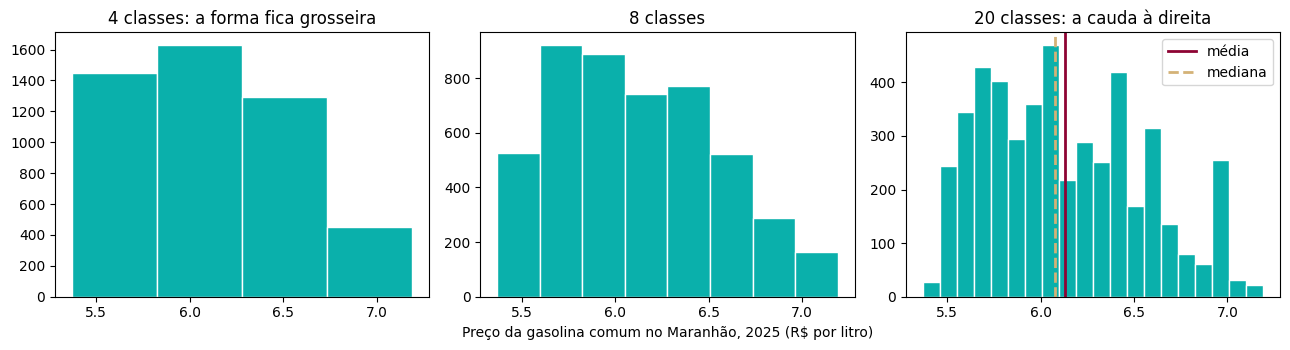

as 20 barras somam 4816 postos-mês


In [75]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
eixos[0].hist(gasolina, bins=4, color="#0AB0AB", edgecolor="white")
eixos[1].hist(gasolina, bins=8, color="#0AB0AB", edgecolor="white")
eixos[2].hist(gasolina, bins=20, color="#0AB0AB", edgecolor="white")
eixos[2].axvline(gasolina.mean(), color="#8D0333", linewidth=2, label="média")
eixos[2].axvline(gasolina.median(), color="#D4B277", linewidth=2, linestyle="--", label="mediana")
eixos[0].set_title("4 classes: a forma fica grosseira")
eixos[1].set_title("8 classes")
eixos[2].set_title("20 classes: a cauda à direita")
eixos[2].legend()
eixos[1].set_xlabel("Preço da gasolina comum no Maranhão, 2025 (R$ por litro)")
plt.tight_layout()
plt.show()
contagens_20, _ = np.histogram(gasolina, bins=20)
print("as 20 barras somam", contagens_20.sum(), "postos-mês")

In [76]:
conferir("soma das barras do histograma (20 classes)", contagens_20.sum(), 4816, tolerancia=0, unidade="")

  [ok] soma das barras do histograma (20 classes)             obtido 4816.0000 esperado 4816.0000


### 4.11 Quartis e o esquema dos cinco números

**Em linguagem corrente.** Os **quartis** dividem os casos em quatro partes iguais. Os
**cinco números** — mínimo, Q1, mediana, Q3, máximo — resumem a distribuição inteira e
servem a **qualquer** forma, inclusive a assimétrica.

**Os cinco números da gasolina.** 5,37 · 5,79 · 6,08 · 6,45 · 7,19.

**Repare.** Da mediana ao Q3 são R$ 0,37; da mediana ao Q1, R$ 0,29. O lado de cima é mais
longo: é a cauda à direita, vista nos números.

In [77]:
cinco = gasolina.quantile([0, 0.25, 0.5, 0.75, 1])
cinco.index = ["mínimo", "Q1", "mediana", "Q3", "máximo"]
print(cinco.round(2).to_string())

mínimo     5.37
Q1         5.79
mediana    6.08
Q3         6.45
máximo     7.19


In [78]:
conferir("mínimo", cinco["mínimo"], 5.37, tolerancia=0.005, unidade=" R$")
conferir("mediana", cinco["mediana"], 6.08, tolerancia=0.005, unidade=" R$")
conferir("máximo", cinco["máximo"], 7.19, tolerancia=0.005, unidade=" R$")

  [ok] mínimo                                                 obtido 5.37 R$   esperado 5.37 R$
  [ok] mediana                                                obtido 6.08 R$   esperado 6.08 R$
  [ok] máximo                                                 obtido 7.19 R$   esperado 7.19 R$


### 4.12 Boxplot: anatomia e o que cada elemento afirma

| Elemento | O que afirma |
|---|---|
| **A caixa** | vai de Q1 a Q3: ali está a metade do meio dos casos (o IQR) |
| **A linha dentro da caixa** | a mediana |
| **Os bigodes** | vão até o último valor dentro das cercas |
| **As cercas** | Q1 − 1,5 × IQR e Q3 + 1,5 × IQR |
| **Os pontos soltos** | valores fora das cercas: candidatos a extremo, a conferir |

**Na gasolina.** As cercas ficam em R$ 4,80 e R$ 7,44, e o posto mais caro (R$ 7,19) está
dentro: **nenhum ponto solto**. O boxplot compara as distribuições de vários grupos lado a
lado, como os três produtos abaixo.

cercas: R$ 4,80 e R$ 7,44 | valores fora das cercas: 0


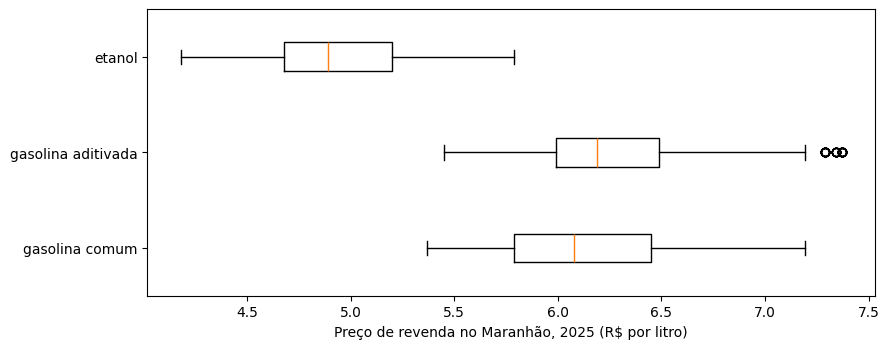

In [79]:
cerca_inf, cerca_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
fora = ((gasolina < cerca_inf) | (gasolina > cerca_sup)).sum()
print("cercas: R$", br(cerca_inf), "e R$", br(cerca_sup), "| valores fora das cercas:", fora)
aditivada = anp.loc[anp["produto"] == "GASOLINA ADITIVADA", "valor_venda"].dropna()
etanol = anp.loc[anp["produto"] == "ETANOL", "valor_venda"].dropna()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([gasolina, aditivada, etanol], vert=False)
ax.set_yticks([1, 2, 3], ["gasolina comum", "gasolina aditivada", "etanol"])
ax.set_xlabel("Preço de revenda no Maranhão, 2025 (R$ por litro)")
plt.tight_layout()
plt.show()

In [80]:
conferir("cerca superior", cerca_sup, 7.44, tolerancia=0.005, unidade=" R$")
conferir("valores fora das cercas", fora, 0, tolerancia=0, unidade="")

  [ok] cerca superior                                         obtido 7.44 R$   esperado 7.44 R$
  [ok] valores fora das cercas                                obtido 0.0000    esperado 0.0000


### 4.13 Escore z: a régua que compara escalas diferentes

**Fórmula.**
$$z = \frac{x - \bar{x}}{s}$$

* $x$ é o valor; $\bar{x}$ a média; $s$ o desvio padrão; $z$ é **quantos desvios** o valor
  está acima (positivo) ou abaixo (negativo) da média

**Em linguagem corrente.** Tire a média e divida pelo desvio. O resultado não tem unidade
e por isso compara grandezas diferentes. Referência: cerca de dois terços dos casos entre
−1 e +1, 95% entre −2 e +2; acima de 2 é incomum (exato na curva normal).

**Comparação.** O posto mais caro está a z = +2,52; o IPCA de fevereiro de 2025 (1,31%) está
a z = +3,18 da sua própria série: **mais incomum**, embora sejam unidades diferentes. E vender
gasolina a R$ 6,20 dá z = +0,17: um preço comum, nem caro nem barato.

In [81]:
z = (gasolina - gasolina.mean()) / gasolina.std()
z_620 = (6.20 - gasolina.mean()) / gasolina.std()
z_ipca = (ipca["valor"].max() - media_ipca) / ipca["valor"].std()
print("posto mais barato: z =", br(z.min()), "| posto mais caro: z =", br(z.max()))
print("R$ 6,20: z =", br(z_620), "| IPCA de 1,31%: z =", br(z_ipca))
print("dentro de |z| < 1:", br((z.abs() < 1).mean() * 100, 1), "% (a normal prevê 68,3%)",
      "| dentro de |z| < 2:", br((z.abs() < 2).mean() * 100, 1), "% (prevê 95,4%)")

posto mais barato: z = -1,80 | posto mais caro: z = 2,52
R$ 6,20: z = 0,17 | IPCA de 1,31%: z = 3,18
dentro de |z| < 1: 59,3 % (a normal prevê 68,3%) | dentro de |z| < 2: 96,6 % (prevê 95,4%)


In [82]:
conferir("z do posto mais caro", z.max(), 2.52, tolerancia=0.005, unidade="")
conferir("z de um preço de R$ 6,20", z_620, 0.17, tolerancia=0.005, unidade="")
conferir("z do IPCA de fevereiro de 2025", z_ipca, 3.18, tolerancia=0.005, unidade="")

  [ok] z do posto mais caro                                   obtido 2.5198    esperado 2.5200
  [ok] z de um preço de R$ 6,20                               obtido 0.1690    esperado 0.1700
  [ok] z do IPCA de fevereiro de 2025                         obtido 3.1764    esperado 3.1800


### 4.14 Assimetria e sua assinatura: média, mediana e cauda

**A assinatura.** Numa distribuição **assimétrica à direita**, a cauda se estende para os
valores altos, os casos distantes puxam a média e **média > mediana**. À esquerda, o
contrário. O coeficiente de assimetria resume isso: 0 é simétrica; positivo, cauda à
direita.

**Na gasolina.** Média R$ 6,13 > mediana R$ 6,08, assimetria de **0,40**: cauda à direita.
Por isso a maioria dos postos cobra **menos** que a média, e o preço típico é a mediana.

**Frase.** “A distribuição dos preços da gasolina no Maranhão em 2025 é assimétrica à
direita (assimetria de 0,40): a média (R$ 6,13) supera a mediana (R$ 6,08), e metade dos
postos está entre R$ 5,79 e R$ 6,45 (ANP).”

In [83]:
assimetria = gasolina.skew()
abaixo_da_media = (gasolina < gasolina.mean()).mean() * 100
print("média R$", br(gasolina.mean()), "| mediana R$", br(gasolina.median()), "| assimetria", br(assimetria))
print("postos abaixo da média:", br(abaixo_da_media, 1), "%  (mais da metade, por causa da cauda)")

média R$ 6,13 | mediana R$ 6,08 | assimetria 0,40
postos abaixo da média: 55,2 %  (mais da metade, por causa da cauda)


In [84]:
conferir("assimetria do preço da gasolina", assimetria, 0.40, tolerancia=0.005, unidade="")

  [ok] assimetria do preço da gasolina                        obtido 0.4028    esperado 0.4000


---

## Fecho · A tabela de decisão: nível → posição → dispersão → gráfico

A tabela que resume o Módulo I. Leia da esquerda para a direita: **o nível da variável
decide a medida de posição, a medida de dispersão e o gráfico.** Depois, a forma da
distribuição decide entre média e mediana.

| Nível | Exemplo do Módulo I | Medida de posição | Medida de dispersão | Gráfico |
|---|---|---|---|---|
| **Nominal** | seção da CNAE (2.1) | **moda**; frequência e % (1.4 a 1.6, 3.5) | não há dispersão numérica: descreva a distribuição das % por categoria | **barras**, ordenadas pela frequência |
| **Ordinal** | faixa de pessoal (2.2) | **mediana** (3.4) e moda | as faixas de Q1 e Q3; a **frequência acumulada** (2.9) | **barras na ordem natural** das categorias |
| **Intervalo** | satisfação de 0 a 10 (2.5) | **média** se simétrica; **mediana** se assimétrica (3.6) | **desvio padrão** (4.4) e **IQR** (4.6); o CV não, porque o zero é convenção | **histograma** (4.10) e **boxplot** (4.12) |
| **Razão** | preço, receita, nº de empresas, IPCA (2.3, 2.4) | **média** se simétrica; **mediana** se assimétrica ou com extremos (3.7, 4.14) | **desvio padrão** (4.4), **CV** para comparar escalas (4.5), **IQR** com extremos (4.6, 4.7) | **histograma** (4.10) e **boxplot** (4.12) |

**E a forma decide o par de medidas**

| A distribuição é… | Como se sabe | Descreva com |
|---|---|---|
| Simétrica, sem extremos | média ≈ mediana (3.8); histograma espelhado; assimetria perto de 0 | **média e desvio padrão** |
| Assimétrica ou com extremos | média longe da mediana; cauda no histograma; pontos soltos no boxplot | **mediana e IQR** (com a média ao lado, dizendo por quê) |

> **A frase que vai para o relatório tem sempre três partes:** o **centro**, a
> **dispersão** e a **origem** (fonte, recorte e período). Exemplo: “Os 4.816 preços de
> gasolina comum no Maranhão em 2025 tiveram mediana de R$ 6,08, com metade dos postos
> entre R$ 5,79 e R$ 6,45 (ANP, SHPC).”